# EDA of the Abalone dataset

# Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)

# Data

In [2]:
df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 297.9 KB


In [4]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


# EDA

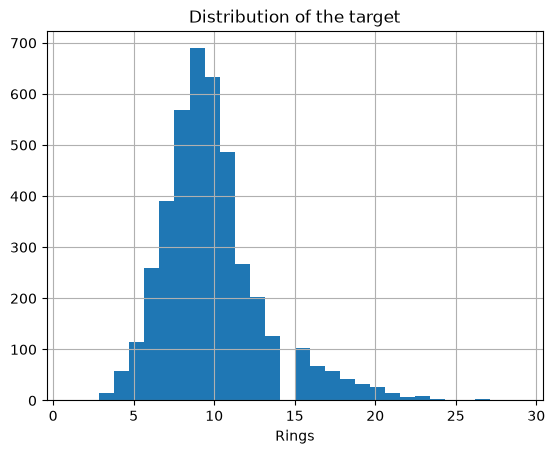

In [5]:
df["Rings"].hist(bins=30)
plt.xlabel("Rings")
plt.title("Distribution of the target")
plt.show()

In [6]:
df["Sex"].value_counts()

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

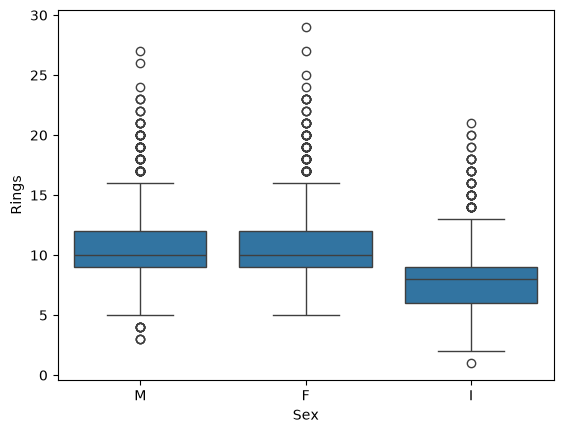

In [7]:
sns.boxplot(data=df, x="Sex", y="Rings")
plt.show()

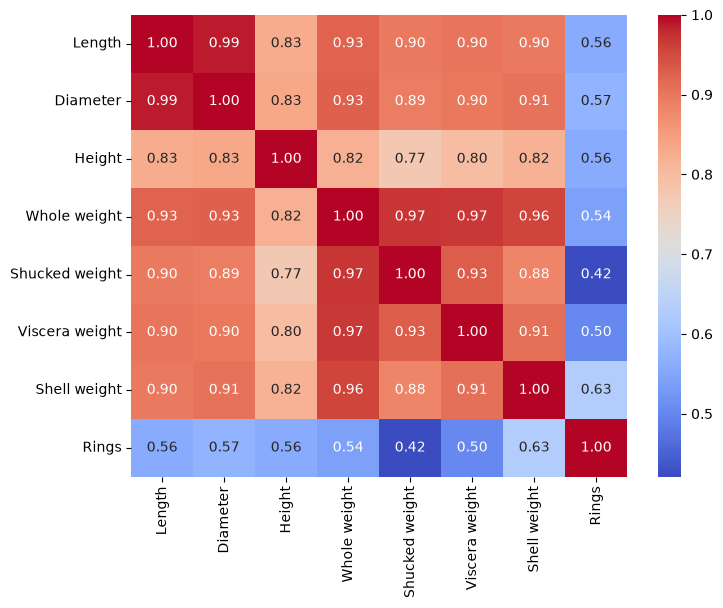

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns="Sex").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

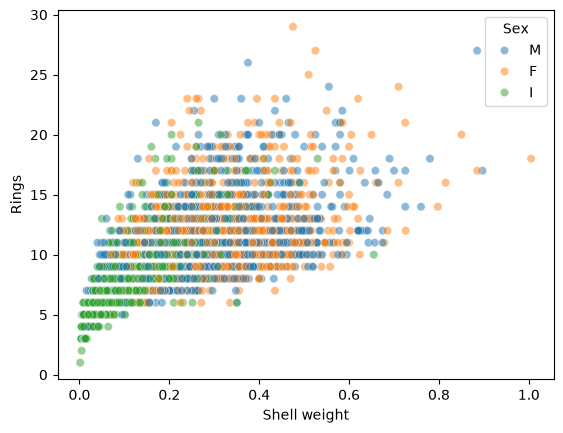

In [9]:
sns.scatterplot(data=df, x="Shell weight", y="Rings", hue="Sex", alpha=0.5)
plt.show()

In [10]:
df[df["Height"] == 0]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


# Conclusions

- 4177 rows and no missing values. The target is `Rings` (age = rings + 1.5).
- 92% of the abalones have between 5 and 15 rings, with a long tail on the right (max 29).
- Infants (I) have fewer rings than males and females, which look very similar.
- The size and weight features are all very correlated with each other (0.77 to 0.99), so a linear model will have collinear features. Shell weight is the most correlated with the target (0.63).
- Two rows have a height of 0 and one has a height of 1.13, probably errors. I keep them for the first model.